This notebook accompanies [17-inverse-problems](https://xing-phys.github.io/ai-for-physics/17-inverse-problems.html). Run cells from top to bottom. The web chapter provides typeset citations and numbered cross-references. Teaching code: MIT; text and figures: CC BY 4.0. All data are generated locally.


# What can measurements tell us? Inverse problems {#discovery-inverse}

A detector measures an intensity, a voltage, or a sequence of clicks. The desired answer is usually something else: a density profile, a Hamiltonian coupling, a source mass, or the quantum state before measurement. A **forward problem** predicts observations from a proposed physical system. An **inverse problem** infers possible systems from observations. The distinction matters because a perfectly accurate forward simulator can have a fundamentally ambiguous inverse.

This chapter develops that ambiguity before introducing learning methods. Its central question is not “which network predicts the parameters?” but “which physical distinctions are supported by these measurements?” We will connect singular values, regularization, Bayesian uncertainty, quantum tomography, and simulation-based inference. All probabilities below refer to an explicitly specified model; they do not automatically account for mistakes in the model itself.

## Information lost by the measurement

Consider a discretized linear experiment,

$$
y=A\theta+\epsilon,
$$

where $\theta\in\mathbb R^p$ contains unknown physical parameters, $y\in\mathbb R^n$ is measured, $A$ is a known response matrix, and $\epsilon$ is measurement noise. A blurred image, line-integrated density measurement, and weak-signal spectroscopy can all have this form. If two parameter vectors differ by $v$ with $Av=0$, their predicted data agree exactly. The set of such $v$ is the **null space**. No learning algorithm can distinguish these vectors using $y$ alone.

A problem is well posed if a solution exists, is unique, and changes continuously under small changes of data. Failure of the third condition is common even when the first two hold. To see why, write the singular value decomposition

$$
A=U\Sigma V^T,\qquad Av_j=s_j u_j.
$$

Here the columns of $U,V$ are orthonormal measurement and parameter directions, and $s_j\geq0$ are singular values. Multiplying the observation by $u_j^T$ gives $u_j^Ty=s_jv_j^T\theta+u_j^T\epsilon$. Inverting a nonzero mode gives

$$
\widehat\theta_j=\frac{u_j^Ty}{s_j}
=v_j^T\theta+\frac{u_j^T\epsilon}{s_j}.
$$

If noise has covariance $\sigma^2I$, the variance of this estimate is $\sigma^2/s_j^2$. A small singular value amplifies noise. This is a property of the experiment, before choosing an estimator.

For a concrete calculation take $A=\operatorname{diag}(1,0.01)$, $\theta=(1,1)^T$, and noise $(0.01,-0.01)^T$. The data are $(1.01,0)^T$. Direct inversion returns $(1.01,0)^T$: a one percent measurement perturbation has erased the second inferred component. Measuring more accurately, modifying $A$, or adding justified prior information can help. A larger neural network cannot restore the missing information without importing assumptions.

## Regularization as an explicit physical assumption

A useful estimate minimizes

$$
L(\theta)=\|A\theta-y\|^2+\lambda\|\theta\|^2,
\qquad\lambda>0.
$$

Differentiating each quadratic term gives $\nabla L=2A^T(A\theta-y)+2\lambda\theta$. Setting this to zero yields

$$
\widehat\theta_\lambda=(A^TA+\lambda I)^{-1}A^Ty
=\sum_j\frac{s_j}{s_j^2+\lambda}(u_j^Ty)v_j.
$$

The factor $s_j/(s_j^2+\lambda)$ stays finite when $s_j$ becomes small. Compared with direct inversion, each resolvable mode is multiplied by $s_j^2/(s_j^2+\lambda)$. Stability is purchased by bias toward zero. If the expected field is smooth, replace $\|\theta\|^2$ by $\|D\theta\|^2$, where $D$ is a discrete derivative. Now the assumption is small gradients rather than small amplitudes. Boundary conventions in $D$ are part of the physical model.

A **learned prior** makes a richer assumption: physical objects resemble the training distribution. This can be powerful for reconstructing detector images or quantum states from few measurements. It can also suppress an unfamiliar defect or phase. A convincing reconstruction therefore includes predicted measurements $A\widehat\theta$, residuals, uncertainty along weakly constrained directions, and tests on objects outside the training families. Agreement with measurements is necessary but does not remove a null-space ambiguity.

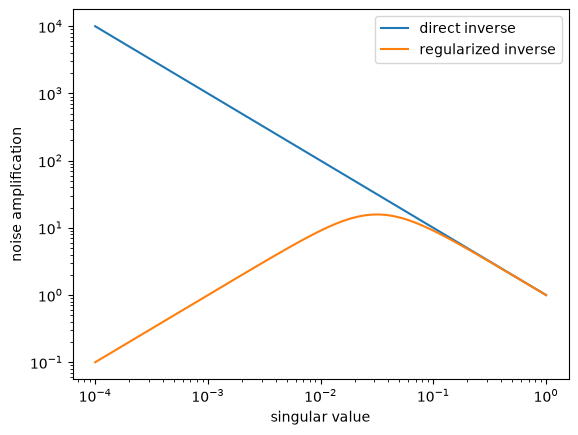

In [1]:
import numpy as np
import matplotlib.pyplot as plt

A = np.diag([1.0, 0.01])
truth = np.array([1.0, 1.0])
y = A @ truth + np.array([0.01, -0.01])
lam = 1e-3
naive = np.linalg.solve(A, y)
regularized = np.linalg.solve(A.T @ A + lam*np.eye(2), A.T @ y)
assert np.allclose(naive, [1.01, 0.0])
assert np.linalg.norm(regularized) < np.linalg.norm(naive)
s = np.geomspace(1e-4, 1, 200)
plt.loglog(s, 1/s, label="direct inverse")
plt.loglog(s, s/(s*s+lam), label="regularized inverse")
plt.xlabel("singular value"); plt.ylabel("noise amplification")
plt.legend(); plt.show()

The second regularized component remains zero. Regularization has prevented instability; it has not reconstructed an unobserved component.

## Bayesian inversion, derived from the data model

Let $p(\theta)$ describe parameter uncertainty before these observations and $p(y\mid\theta)$ describe the measurement process. Their product is a joint distribution: $p(\theta,y)=p(y\mid\theta)p(\theta)$. Dividing by the marginal probability of the observed data produces Bayes' rule,

$$
p(\theta\mid y)=\frac{p(y\mid\theta)p(\theta)}{p(y)},\qquad
p(y)=\int p(y\mid\theta)p(\theta)\,d\theta.
$$

The likelihood is a function of candidate parameters with the measured data fixed; it is not itself a probability distribution over parameters. The posterior is such a distribution after normalization.

Suppose $\epsilon\sim\mathcal N(0,C)$ and $\theta\sim\mathcal N(m_0,S_0)$, with positive definite covariances. Apart from constants, minus twice the log posterior is

$$
(y-A\theta)^TC^{-1}(y-A\theta)
+(\theta-m_0)^TS_0^{-1}(\theta-m_0).
$$

Expanding gives a quadratic coefficient $A^TC^{-1}A+S_0^{-1}$ and a linear term $-2\theta^T(A^TC^{-1}y+S_0^{-1}m_0)$. Completing the square establishes

$$
S=(S_0^{-1}+A^TC^{-1}A)^{-1},\qquad
m=S(S_0^{-1}m_0+A^TC^{-1}y).
$$ 

Thus $p(\theta\mid y)=\mathcal N(m,S)$. Its mean and maximum coincide because it is Gaussian. For $m_0=0$, $C=\sigma^2I$, and $S_0=\tau^2I$, its mean equals the regularized estimate with $\lambda=\sigma^2/\tau^2$. This equivalence identifies the assumption behind that particular penalty. It does not imply every regularizer gives meaningful uncertainty.

For a single unknown offset $\theta$ measured $n$ times with independent variance $\sigma^2$, prior variance $\tau^2$, and zero prior mean, the posterior variance is $(\tau^{-2}+n\sigma^{-2})^{-1}$. The posterior mean is that variance times $n\bar y/\sigma^2$. With $n=4$, $\sigma=2$, $\tau=3$, and $\bar y=1$, these are $S=0.9$ and $m=0.9$. The prior pulls the estimate slightly toward zero. A posterior probability interval is a statement conditional on this prior and noise model. Its repeated-experiment coverage must be checked under the relevant deployment conditions.

## Sensitivity, Fisher information, and nuisance parameters

For nonlinear measurements $y=f(\theta)+\epsilon$, locally expand about $\theta_0$:

$$
f(\theta_0+\delta\theta)\approx f(\theta_0)+J\delta\theta,
\qquad J_{ia}=\frac{\partial f_i}{\partial\theta_a}.
$$

The Jacobian describes sensitivity. With parameter-independent Gaussian covariance $C$, the local likelihood curvature is $J^TC^{-1}J$. More generally define the **score** $s_a=\partial_{\theta_a}\log p(y\mid\theta)$ and the **Fisher information**

$$
F_{ab}=\mathbb E_{y\mid\theta}[s_as_b].
$$

In the Gaussian case $s=J^TC^{-1}(y-f)$, so taking the noise average gives $F=J^TC^{-1}J$. Under differentiability, parameter-independent support, and regularity assumptions, an unbiased estimator has covariance at least $F^{-1}$ in the positive-semidefinite sense. This is a local lower bound, not a promise that an estimator achieves it. Bias, multiple posterior peaks, parameter boundaries, and model errors require separate treatment.

::: {.callout-note title="Optional derivation: why information bounds variance"}
For a scalar parameter and an unbiased estimator $T(y)$, differentiating $\int T(y)p(y\mid\theta)dy=\theta$ gives $\mathbb E[T s]=1$. Differentiating normalization gives $\mathbb E[s]=0$, so $\mathbb E[(T-\theta)s]=1$. Cauchy–Schwarz then gives $1\leq\mathbb E[(T-\theta)^2]\mathbb E[s^2]=\operatorname{Var}(T)F$. Interchanging derivative and integral and using parameter-independent support are the regularity assumptions behind this calculation. An unbiased estimator of a parameter at a distribution boundary need not satisfy them.

For a vector estimator error $e=T-\theta$, the same differentiation gives $\mathbb E[e s^T]=I$. The covariance of $e-F^{-1}s$ is positive semidefinite. Expanding it yields $\operatorname{Cov}(T)-F^{-1}$, establishing the matrix bound when $F$ is invertible. Singular information instead signals locally unresolved parameter directions; it does not justify taking an ordinary inverse.
:::

Suppose $y_i=a+bt_i+\epsilon_i$. Then

$$
F=\sigma^{-2}\begin{pmatrix}n&\sum_i t_i\\\sum_i t_i&\sum_i t_i^2\end{pmatrix}.
$$

If the offset $a$ is unknown, the effective information about $b$ is the Schur complement

$$
F_{b\mid a}=\sigma^{-2}\left[\sum_i t_i^2-\frac{(\sum_i t_i)^2}{n}\right]
=\sigma^{-2}\sum_i(t_i-\bar t)^2.
$$

To obtain this result, invert the two-by-two matrix and identify the variance bound for $b$. Closely clustered times poorly distinguish a slope from an offset. Fixing the offset incorrectly would overstate available information. Parameters such as backgrounds, calibration factors, or detector efficiencies that are needed but are not the scientific target are called **nuisance parameters**. Bayesian marginalization integrates over their posterior uncertainty rather than silently fixing them.

## A quantum example: a state is inferred through a measurement model

A qubit state can be written

$$
\rho=\tfrac12(I+r_x\sigma_x+r_y\sigma_y+r_z\sigma_z),
\qquad |\boldsymbol r|\leq1.
$$

The Pauli matrices have eigenvalues $\pm1$. Measuring axis $a$ yields “plus” with probability $p_a=(1+r_a)/2$, since the projector is $(I+\sigma_a)/2$ and $p_a=\operatorname{Tr}(\rho\Pi_a)$. For $k_a$ plus outcomes from $N_a$ independent repetitions, the likelihood contains $p_a^{k_a}(1-p_a)^{N_a-k_a}$, times a binomial coefficient independent of the state.

Measuring $z$ alone determines only $r_z$. It does not determine coherence in $x,y$. Measuring all three axes gives raw estimates $\widehat r_a=2k_a/N_a-1$, but independent sampling errors can produce $|\widehat{\boldsymbol r}|>1$, which would give a negative eigenvalue $(1-|\widehat{\boldsymbol r}|)/2$. A constrained likelihood fit or a prior over positive density matrices restores physicality. Projecting the raw Bloch vector radially onto the sphere is a simple repair but generally is not the binomial maximum-likelihood solution.

For one axis the score for $r$ is $k/(1+r)-(N-k)/(1-r)$. Its Fisher information is $N/(1-r^2)$ for $|r|<1$. The apparent divergence at a pure eigenstate is a boundary effect: the regular unbiased-estimation assumptions need care there. For many-body states, the number of density-matrix entries grows exponentially. Neural representations can help when the target states have exploitable structure; they cannot make arbitrary states identifiable from an insufficient measurement set. Report measurement settings and state-family assumptions with every tomography claim.

## When simulation is available but the likelihood is not

A collider event simulator can generate showering, detector response, and reconstructed tracks. A cosmological simulator can generate a density field. The resulting $p(y\mid\theta)$ may be impossible to evaluate because many hidden random variables must be integrated out. **Simulation-based inference** uses simulated pairs $(\theta,y)$ to learn an approximation useful for inference. The review by Cranmer, Brehmer, and Louppe explains this broad setting [@d-cranmer2020]. Three routes are worth separating.

**Posterior estimation** minimizes $\mathbb E[-\log q_\phi(\theta\mid y)]$ on pairs drawn from $p(\theta)p(y\mid\theta)$. For each $y$, the expectation equals the entropy of the true posterior plus $D_{\mathrm{KL}}(p(\theta\mid y)\|q_\phi(\theta\mid y))$. The entropy is independent of $\phi$, so an expressive, perfectly optimized model would recover the posterior on the training distribution. Finite simulations, limited architectures, and optimization errors prevent that guarantee in practice. Reusing a trained conditional model for many observations is called **amortization**.

**Likelihood estimation** fits $q_\phi(y\mid\theta)$ instead. One then multiplies this approximation by a chosen prior and uses posterior sampling. **Ratio estimation** trains a classifier to distinguish joint pairs from independently shuffled pairs. If the two classes have equal prior probability, its optimal output satisfies

$$
D^*(\theta,y)=\frac{p(\theta,y)}{p(\theta,y)+p(\theta)p(y)},\qquad
\frac{D^*}{1-D^*}=\frac{p(y\mid\theta)}{p(y)}.
$$

This ratio supplies the parameter-dependent part of Bayes' rule without evaluating $p(y)$. Classifier accuracy alone does not establish ratio accuracy in rare posterior tails. Also, a summary statistic $s(y)$ can discard information; inference then targets $p(\theta\mid s)$ unless the summary is sufficient.

Gravitational-wave inference supplies a representative bridge: conditional density estimators were trained on simulated waveforms to accelerate binary-source parameter inference [@d-dax2021]. This is a computational result within waveform, prior, and detector-noise assumptions. Agreement with a conventional posterior checks the inference machinery; independent checks of waveform systematics test a different issue.

## Learning a reusable posterior from simulated pairs

A complete small example makes amortization concrete without requiring a density-estimation library. Suppose a simulator draws $\theta\sim\mathcal N(0,\tau^2)$, then returns $y=\theta+\epsilon$ with independent $\epsilon\sim\mathcal N(0,\sigma^2)$. We deliberately choose a case with an analytic answer so that the learned inference can be checked independently. During training the estimator uses only simulated pairs, not likelihood evaluations.

Fit a conditional Gaussian

$$
q_\phi(\theta\mid y)=\mathcal N(ay+b,v),\qquad v>0,
$$

with learned parameters $\phi=(a,b,v)$. For $N$ pairs, its negative log likelihood, apart from a constant, is

$$
\mathcal L=\frac N2\log v+\frac{1}{2v}\sum_{i=1}^N[\theta_i-(ay_i+b)]^2.
$$

At fixed $v$, minimizing this objective is ordinary least squares with design rows $(y_i,1)$. Its normal equations determine $a,b$. Differentiating with respect to $v$ gives $N/(2v)-\sum_i[\theta_i-(ay_i+b)]^2/(2v^2)=0$, so the fitted variance is the mean squared training residual. The denominator $N$ is the maximum-likelihood choice; it is not the degrees-of-freedom correction used for an unbiased residual-variance estimator.

Completing the square as in @eq-discovery-gaussian-posterior gives the exact target

$$
a_* =\frac{\tau^2}{\tau^2+\sigma^2},\qquad b_*=0,\qquad
v_*=\frac{\tau^2\sigma^2}{\tau^2+\sigma^2}.
$$

After fitting once, a new measurement requires only evaluating $ay+b$ and reporting the same conditional variance $v$. That is amortized posterior estimation, albeit in a family simple enough to fit analytically. A neural density estimator replaces this restrictive family when the simulator produces nonlinear, multimodal, or observation-dependent posterior shapes.

In [2]:
import numpy as np
rng = np.random.default_rng(1712)
tau, sigma, n_train = 2.0, 0.7, 30_000
train_theta = rng.normal(0, tau, n_train)
train_y = train_theta+rng.normal(0, sigma, n_train)
design = np.column_stack([train_y, np.ones(n_train)])
a, b = np.linalg.lstsq(design, train_theta, rcond=None)[0]
v = np.mean((train_theta-design @ np.array([a, b]))**2)
a_exact = tau**2/(tau**2+sigma**2)
v_exact = tau**2*sigma**2/(tau**2+sigma**2)
assert abs(a-a_exact) < 0.02 and abs(b) < 0.03
assert abs(v/v_exact-1) < 0.05

def evaluate(noise_sd, n_test=6000):
    theta = rng.normal(0, tau, n_test)
    y = theta+rng.normal(0, noise_sd, n_test)
    residual = theta-(a*y+b)
    # P(|Z| <= 1.959964) = 0.95 for a standard Gaussian Z.
    coverage = np.mean(np.abs(residual) <= 1.959964*np.sqrt(v))
    return coverage, np.mean(residual**2)/v

matched = evaluate(sigma)
changed = evaluate(1.4)  # unchanged estimator; a changed physical noise process
print(f"Slope: learned {a:.5f}; exact {a_exact:.5f}")
print(f"Variance: learned {v:.5f}; exact {v_exact:.5f}")
print(f"Matched noise: coverage {matched[0]:.3f}; error ratio {matched[1]:.3f}")
print(f"Changed noise: coverage {changed[0]:.3f}; error ratio {changed[1]:.3f}")

Slope: learned 0.89277; exact 0.89087
Variance: learned 0.43653; exact 0.43653
Matched noise: coverage 0.946; error ratio 1.024
Changed noise: coverage 0.692; error ratio 3.680


The independent test with matched noise should have coverage near $95\%$, with sampling fluctuations and fitting error; the code does not assert exact coverage of one test sample. Doubling the noise while retaining the trained estimator generally causes substantial undercoverage. This is a physical-model change, even though the inference code still runs correctly. Indeed, under test noise $\sigma_{\mathrm{test}}$ its residual has mean $-b$ and variance $(1-a)^2\tau^2+a^2\sigma_{\mathrm{test}}^2$, obtained by expanding $(1-a)\theta-a\epsilon-b$. That variance need not equal the reported $v$. Retraining with the new noise, or conditioning the estimator on a measured noise descriptor, changes the inference problem appropriately. Better calibration on the old simulator cannot establish robustness to an unmodeled change.

## Calibration is an experiment on the inference algorithm

**Simulation-based calibration** repeats the complete generative and inferential process. Draw $\theta^{(r)}$ from the prior, draw $y^{(r)}$ from the simulator, obtain $M$ independent posterior samples, and count how many samples of a scalar parameter fall below its generating value. Under an exact continuous posterior, the true value and posterior samples are exchangeable conditional on the data; consequently its rank is uniform on $0,\ldots,M$. Nonuniform rank histograms reveal inconsistency. Uniform ranks do not prove the physical simulator matches nature, nor do marginal ranks exhaust all multivariate errors [@d-talts2018].

The following executable check uses a conjugate Gaussian model, where inference is exact. A central $95\%$ interval is $m\pm1.959964\sqrt S$; this Gaussian quantile is supplied numerically. Coverage is averaged over prior-generated truths, not asserted for every fixed truth.

In [3]:
import numpy as np
rng = np.random.default_rng(1701)
R, M = 4000, 49
prior_sd, noise_sd = 2.0, 0.7
truth = rng.normal(0, prior_sd, R)
data = truth + rng.normal(0, noise_sd, R)
var = 1/(1/prior_sd**2 + 1/noise_sd**2)
mean = var*data/noise_sd**2
samples = mean[:, None] + np.sqrt(var)*rng.normal(size=(R, M))
ranks = (samples < truth[:, None]).sum(axis=1)
coverage = np.mean(np.abs(truth-mean) <= 1.959964*np.sqrt(var))
assert abs(coverage-0.95) < 0.025
assert abs(ranks.mean()-M/2) < 1.0
print("prior-averaged coverage:", round(coverage, 3))
print("mean rank:", round(ranks.mean(), 2))

prior-averaged coverage: 0.949
mean rank: 24.69


A second diagnostic is the **posterior predictive distribution** $p(y'\mid y)=\int p(y'\mid\theta)p(\theta\mid y)d\theta$. Generate replicated measurements from posterior draws and compare residual structure, extreme events, and correlations with real observations. Failure may identify an inadequate noise model or missing physics. Success is relative to the discrepancies examined; an unmeasured mode can remain unconstrained.

## Exercises and worked answers

1. For $A=\operatorname{diag}(1,0.01)$ and noise standard deviation $0.02$, calculate the standard deviation of each directly inverted component. What changes if the number of independent repetitions is multiplied by four?
2. Derive the slope variance bound when the measurement times are $-T,0,T$ and an unknown offset is fitted. Compare with three observations all made at $T$.
3. A qubit is measured only in $z$, with equal plus and minus counts. Give two physically different states compatible with the expected outcomes. Design a measurement that distinguishes them.
4. Modify the calibration code to use half the correct posterior standard deviation. Predict the rank histogram and coverage before running it.

**Answers.** In exercise 1 the standard deviations are $0.02$ and $2$ because noise is divided by the singular value. Fourfold repetition divides both by two, assuming independent noise. In exercise 2, $\bar t=0$ and $F_{b\mid a}=2T^2/\sigma^2$, so $\operatorname{Var}(\widehat b)\geq\sigma^2/(2T^2)$. Coincident times make the information zero; offset and slope are inseparable. In exercise 3, $I/2$ and $(I+\sigma_x)/2$ both have $r_z=0$; measuring $x$ gives plus probabilities $1/2$ and $1$. In exercise 4 underdispersion places too many generating values beyond the approximate posterior tails, producing excess extreme ranks and low interval coverage. These are algorithm diagnostics under the assumed generative model.